<a href="https://colab.research.google.com/github/JLettsSJU931/Machine-Learning-FA26/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Task 1: Dataset Loading and Dimensionality Inspection** Load the Olivetti Faces dataset using sklearn.datasets.fetch_olivetti_faces. Print the total number of samples, unique target subjects, feature dimensions, and plot a 4 x 5 grid of sample faces labeled with their subject IDs.

Here I load in the dataset and map values to x, y, and for the images. I then print out as many unique faces I can onto the 4x5 grid, since there are 10 photos per subject I multiply the index by 10 when finding a photo.

Sample Count: 400
Target Count: 40
Feature dimensions: 4096
Image dimensions: (64, 64)


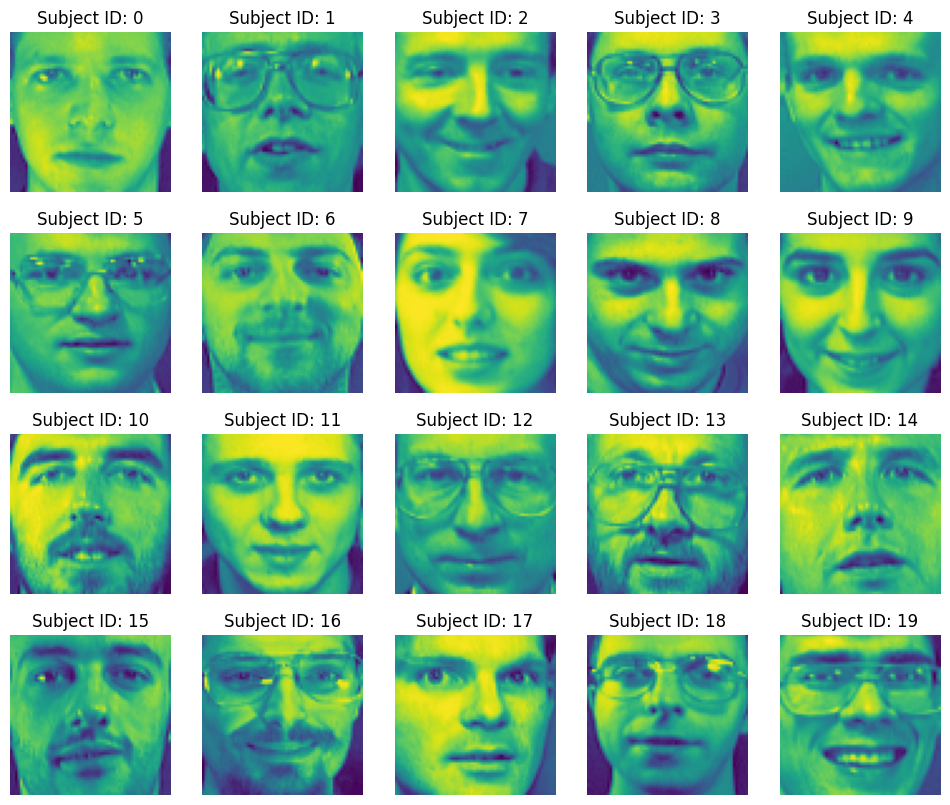

In [134]:
from sklearn.datasets import fetch_olivetti_faces
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = fetch_olivetti_faces()

x = df.data
y= df.target
image = df.images

print("Sample Count:", x.shape[0])
print("Target Count:", len(set(y)))
print("Feature dimensions:", x.shape[1])
print("Image dimensions:", image.shape[1:])

fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for i, axes in enumerate(axes.flat):
  axes.imshow(image[(10*i)])
  axes.set_title(f"Subject ID: {y[(10*i)]}")
  axes.axis("off")

# **Task 2: Cumulative Explained Variance & Elbow Plot** Fit a full PCA model on the dataset. Plot both the individual explained variance ratio and the cumulative explained variance curve versus the number of principal components. Determine and print the exact number of components required to preserve 90%, 95%, and 99% of the cumulative variance.

Here I make a Principle Component Analysis (PCA) and fit x to it. I then find the cumulative variance ratio and use the three variances given in a loop to check the components for each. Finally I plot my results on two graphs against the numer of principal components to compare and contrast the results.

90.0 % variance
66  components
cumulative variance =  0.9002 %
95.0 % variance
123  components
cumulative variance =  0.9504 %
99.0 % variance
260  components
cumulative variance =  0.99 %


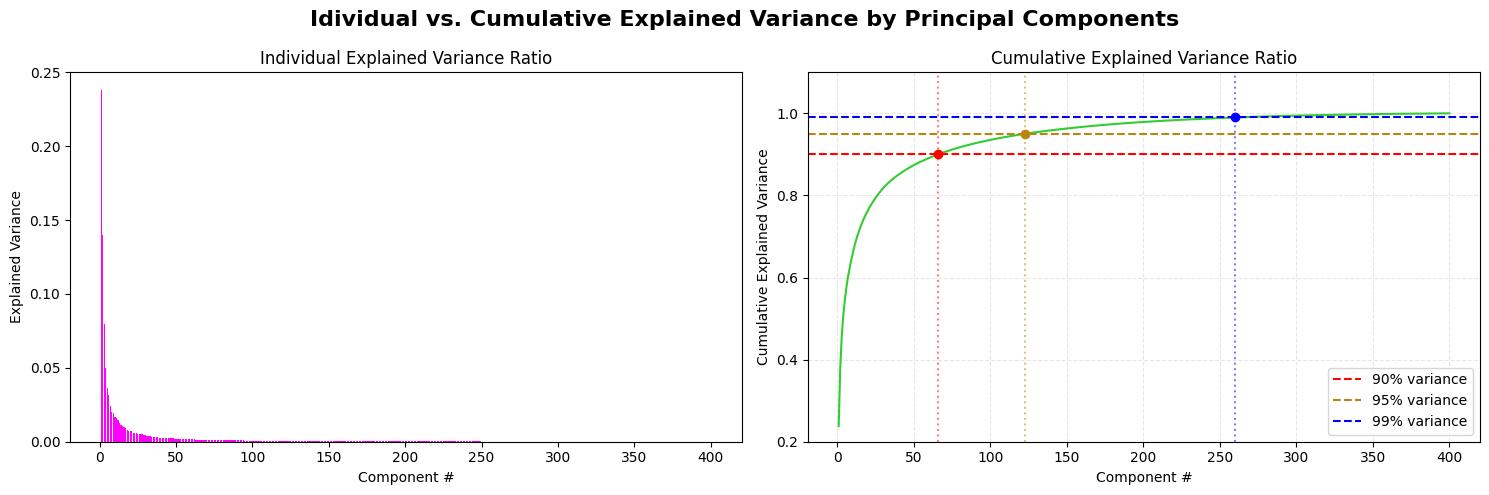

In [135]:
from sklearn.decomposition import PCA

pca = PCA(n_components=None)
pca.fit(x)
exp_var_ratio = pca.explained_variance_ratio_
cum_var_ratio = np.cumsum(exp_var_ratio)
for threshold in [0.90, 0.95, 0.99]:
  n_comp = np.argmax(cum_var_ratio >= threshold) + 1
  true_var = cum_var_ratio[n_comp - 1]
  print(np.round(threshold * 100), "% variance")
  print(np.round(n_comp,0)," components")
  print("cumulative variance = ", np.round(true_var,4), "%")
comp =  np.arange(1, len(exp_var_ratio) + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Idividual vs. Cumulative Explained Variance by Principal Components', fontsize=16, fontweight='bold')
axes[0].bar(comp, exp_var_ratio, color="magenta", linewidth=0.5)
axes[0].set_title("Individual Explained Variance Ratio")
axes[0].set_xlabel("Component #")
axes[0].set_ylabel("Explained Variance")
axes[1].plot(comp, cum_var_ratio, color="limegreen")
colors = ["red", "darkgoldenrod", "blue"]
for threshold, color in zip([0.90, 0.95, 0.99], colors):
  n = np.argmax(cum_var_ratio >= threshold) + 1
  axes[1].axhline(y=threshold, color=color, linestyle="--", label=f"{threshold:.0%} variance")
  axes[1].axvline(x=n, color=color, linestyle=":", alpha=0.5)
  axes[1].scatter(n, cum_var_ratio[n - 1], color=color, zorder=3)
axes[1].set_title("Cumulative Explained Variance Ratio")
axes[1].set_xlabel("Component #")
axes[1].set_ylabel("Cumulative Explained Variance")
axes[1].set_ylim(0.2, 1.1)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# **Task 3: Image Compression and Reconstruction Analysis** Select 5 representative facial images. Compress and reconstruct them using PCA with varying numbers of components; e.g., k in {10, 50, 100, 200, 300}. Plot a grid comparing the original images against their reconstructions across each component threshold, and compute/plot the Mean Squared Error (MSE) between original and reconstructed faces as a function of k.

I select 5 images from the faces that I enjoyed and compress them in a loop, while also going through a process to reconstruct the faces using the varying number of components shown.

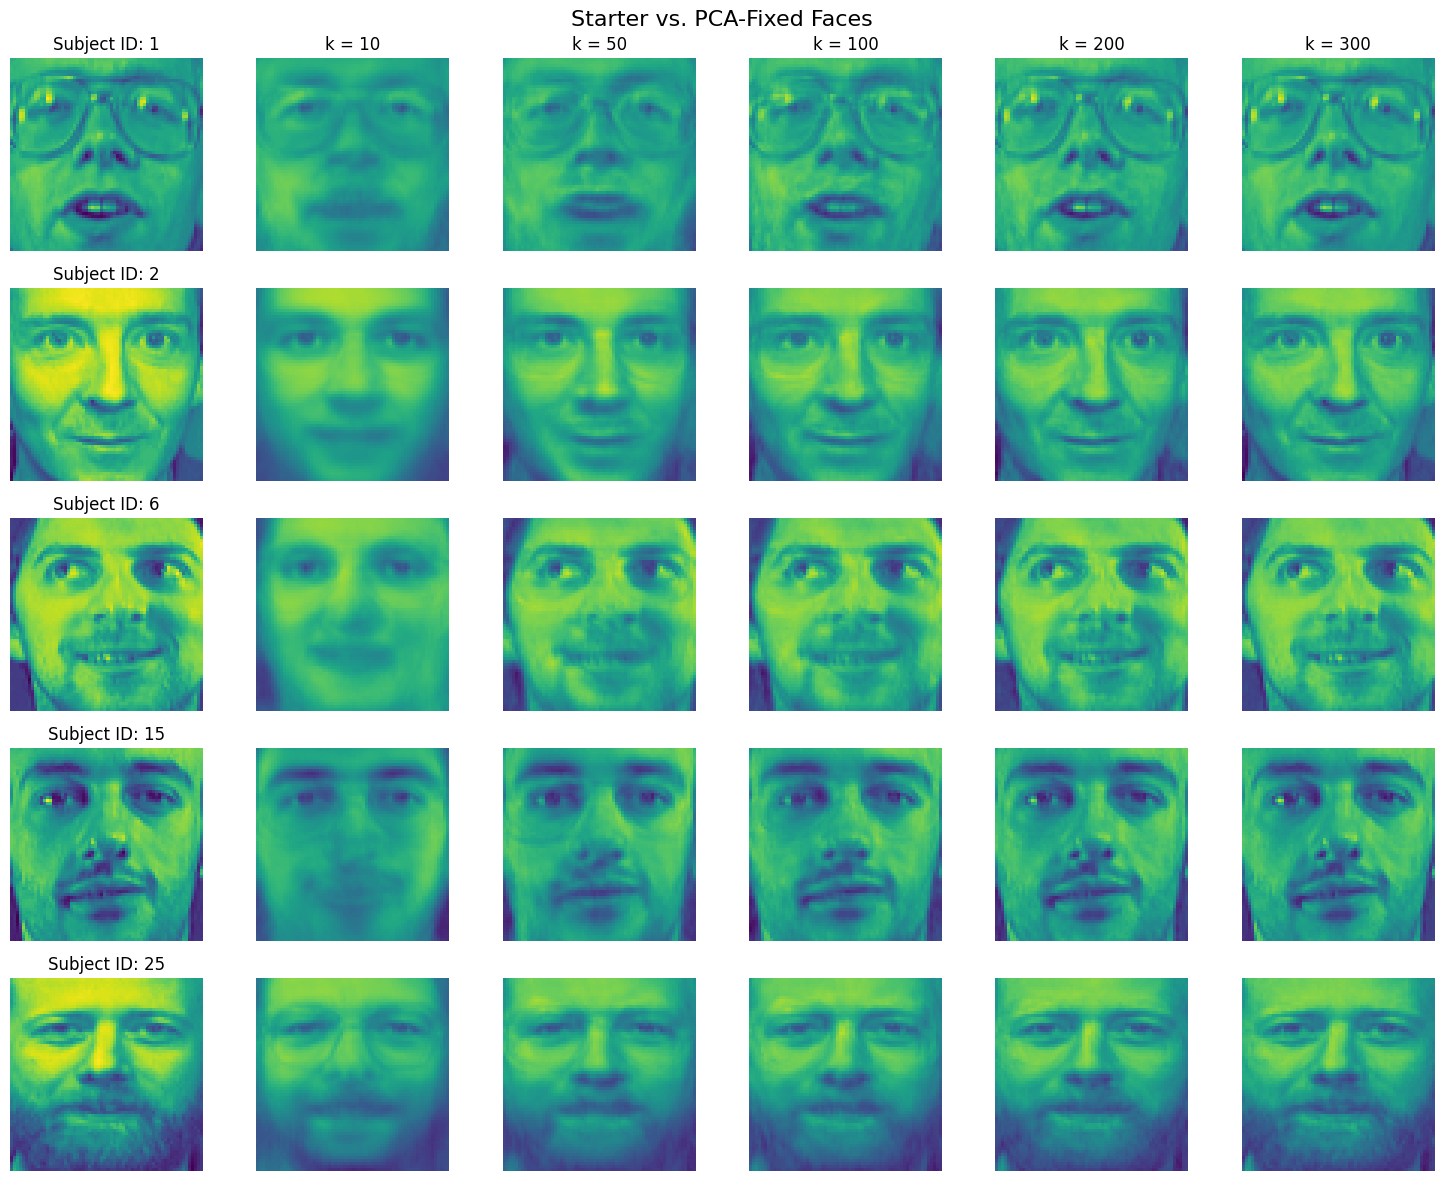

Mean Squared Error (MSE) by number of components:
level =  10: MSE = 0.007781
level =  50: MSE = 0.002620
level = 100: MSE = 0.001278
level = 200: MSE = 0.000401
level = 300: MSE = 0.000092


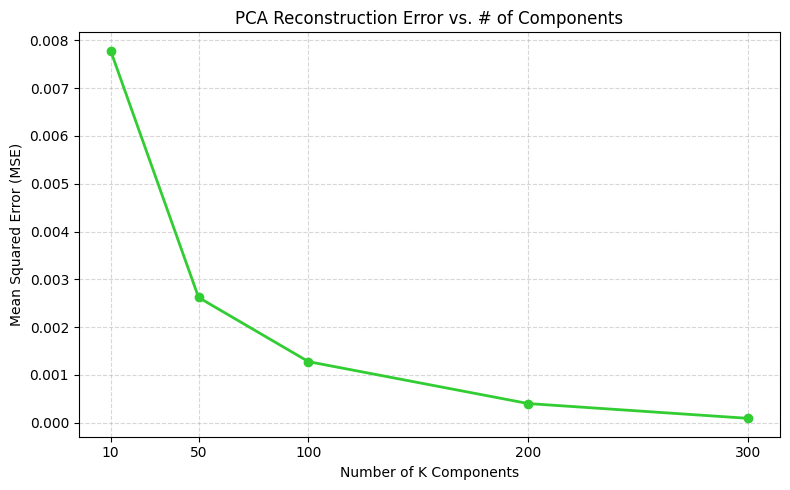

In [136]:
from sklearn.metrics import mean_squared_error

comp_level = [10, 50, 100, 200, 300]
pca_fixer = PCA(n_components=max(comp_level))
pca_fixer.fit(x)
test_subs = [14, 28, 62, 150, 250]
starter_face = x[test_subs]
fixes = {}
mse_list = []
for k in comp_level:
  k_pca = PCA(n_components=k)
  k_pca.fit(x)
  pixel = k_pca.transform(starter_face)
  fixed = k_pca.inverse_transform(pixel)
  fixes[k] = fixed
  mse = mean_squared_error(starter_face.ravel(), fixed.ravel())
  mse_list.append(mse)
fig, axes = plt.subplots(len(test_subs), len(comp_level) + 1, figsize=(15, 12))
for row, idx in enumerate(test_subs):
  axes[row, 0].imshow(df.images[idx])
  axes[row, 0].set_title(f"Subject ID: {df.target[idx]}")
  axes[row, 0].axis("off")
  for col, k in enumerate(comp_level, start=1):
    fixed_face = fixes[k][row].reshape(64, 64)
    axes[row, col].imshow(fixed_face, vmin=0, vmax=1)
    if row == 0:
      axes[row, col].set_title(f"k = {k}")
    axes[row, col].axis("off")
plt.suptitle("Starter vs. PCA-Fixed Faces", fontsize=16)
plt.tight_layout()
plt.show()
print("Mean Squared Error (MSE) by number of components:")
for k, mse in zip(comp_level, mse_list):
  print(f"level = {k:3d}: MSE = {mse:.6f}")
plt.figure(figsize=(8, 5))
plt.plot(comp_level, mse_list, marker="o", linewidth=2, color="limegreen")
plt.xlabel("Number of K Components")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("PCA Reconstruction Error vs. # of Components")
plt.xticks(comp_level)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# **Task 4: Visualization of "Eigenfaces"** Extract the principal components (eigenvectors) from your fitted PCA model. Reshape the first 15 principal components back into 64 x 64 grids and visualize them in a 3 x 5  plot grid ("Eigenfaces"). Annotate each plot with the percentage of total variance explained by that specific component.

Here I go through the process of visualizing the levels of variance in the principle components shown, which here is called eigenfaces.

Eigenfaces shape: (15, 4096)


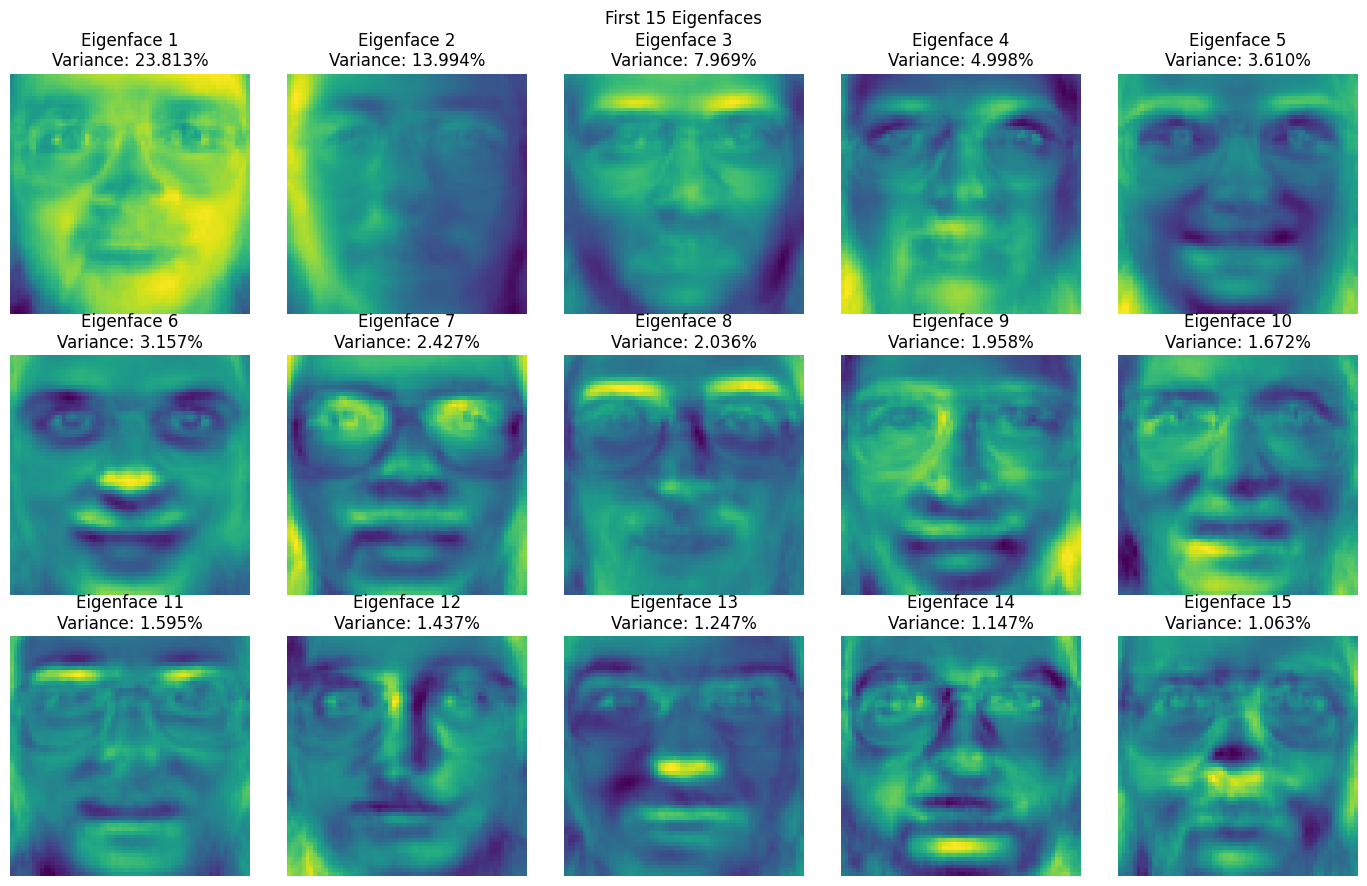

In [137]:
eigens = pca.components_[:15]
eigen_var_ratio = pca.explained_variance_ratio_[:15] * 100
print("Eigenfaces shape:", eigens.shape)
fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for i, ax in enumerate(axes.flat):
  eigen = eigens[i].reshape(64, 64)
  ax.imshow(eigen)
  ax.set_title(f"Eigenface {i + 1}\nVariance: {eigen_var_ratio[i]:.3f}%")
  ax.axis("off")

fig.suptitle("First 15 Eigenfaces", fontsize=12)
plt.tight_layout()
plt.show()

# **Task 5: Classification Baseline — Raw vs. PCA-Reduced Features (Linear Model)** Perform a stratified train/test split (80/20). Train a LogisticRegression classifier on:
## 1. The raw 4,096-dimensional feature vectors.
## 2. The PCA-reduced feature vectors using the 95% variance threshold fitted strictly on the training set
# Evaluate and print the test accuracy and training time for both, and visualize the performance comparison in a dual-axis bar plot (Accuracy vs. Training Time).

Here I trained two sets of data: first the raw, unreduced data, then the same data but PCA reduced by 95%. I timed the length of both processes using the time import, as well as found the accuracy score of both. Finally, I go through a lot of hoops to create a dual-axis plot to compare the raw and pca test efficiency.

Training classifier on raw features...
Test Accuracy:  0.975
Test Time:  23.583781003952026

Training classifier on PCA-reduced features...
Test Accuracy:  0.975
Test Time:  0.7788662910461426


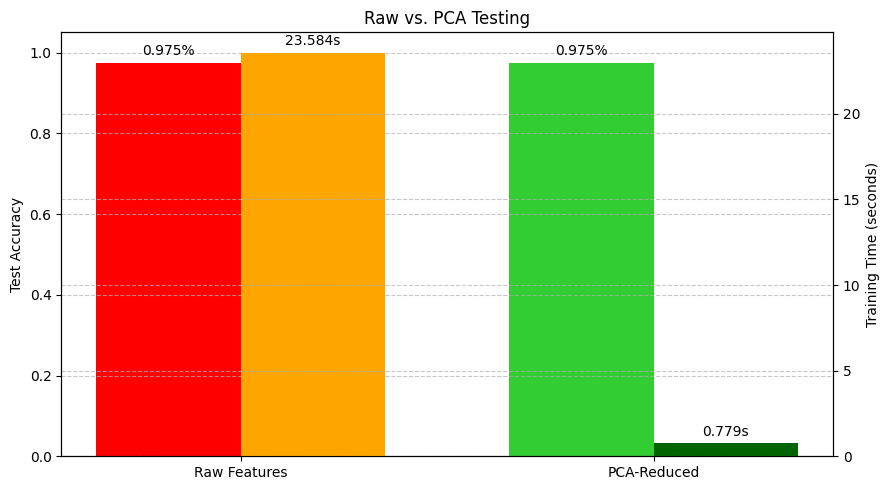

In [138]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=69, stratify=y)
print("Training classifier on raw features...")
start_time = time.time()
clf_raw = LogisticRegression(max_iter=1000, random_state=69)
clf_raw.fit(X_train, y_train)
raw_time = time.time() - start_time
y_pred_raw = clf_raw.predict(X_test)
raw_accuracy = accuracy_score(y_test, y_pred_raw)
print('Test Accuracy: ', raw_accuracy)
print('Test Time: ', raw_time)

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=69, stratify=y)
print("\nTraining classifier on PCA-reduced features...")
start_time = time.time()
pca_clf = PCA(n_components=0.95)
X_train_pca = pca_clf.fit_transform(X_train)
X_test_pca = pca_clf.transform(X_test)
clf_pca = LogisticRegression(max_iter=1000, random_state=69)
clf_pca.fit(X_train_pca, y_train)
pca_time = time.time() - start_time
y_pred_pca = clf_pca.predict(X_test_pca)
pca_accuracy = accuracy_score(y_test, y_pred_pca)
print('Test Accuracy: ', pca_accuracy)
print('Test Time: ', pca_time)

fig, ax1 = plt.subplots(figsize=(9, 5))
width = 0.35
labels = ["Raw Features", "PCA-Reduced"]
positions = np.arange(len(labels))
bars_acc = ax1.bar(positions - width / 2, [raw_accuracy, pca_accuracy], width, color=["red", "limegreen"], label="Test Accuracy")
ax1.set_ylabel("Test Accuracy")
ax1.set_title("Raw vs. PCA Testing")
ax1.set_ylim(0, 1.05)
ax1.grid(axis="y", linestyle="--", alpha=0.7)
ax1.set_xticks(positions)
ax1.set_xticklabels(labels)
ax1.bar_label(bars_acc, fmt="%.3f%%", padding=3)
ax2 = ax1.twinx()
positions = np.arange(len(labels))
bars_time = ax2.bar(positions + (width / 2), [raw_time, pca_time], width, color=["orange", "darkgreen"], label = "Test Time")
ax2.set_ylabel("Training Time (seconds)")
ax2.grid(axis="y", linestyle="--", alpha=0.7)
ax2.bar_label(bars_time, fmt="%.3fs", padding=3)
plt.tight_layout()
plt.show()



# **Task 6: Non-Linear Classification (Kernel SVM)** Train a SVC with an RBF kernel on the PCA-reduced features (95% variance). Record its training time and test accuracy, and plot a confusion matrix or classification summary comparing its predictions against the linear baseline.

Here I make a simple SVC pipeline and fit the PCA training data to it, whilst using the time function as seen previous. I then take the PCA predictions and the SVC predictions and put them in a confusion matrix, which is then sent through seaborn and displayed.

Test Accuracy:  1.0
Test Time:  0.20006775856018066
Baseline vs. SVC


<function matplotlib.pyplot.show(close=None, block=None)>

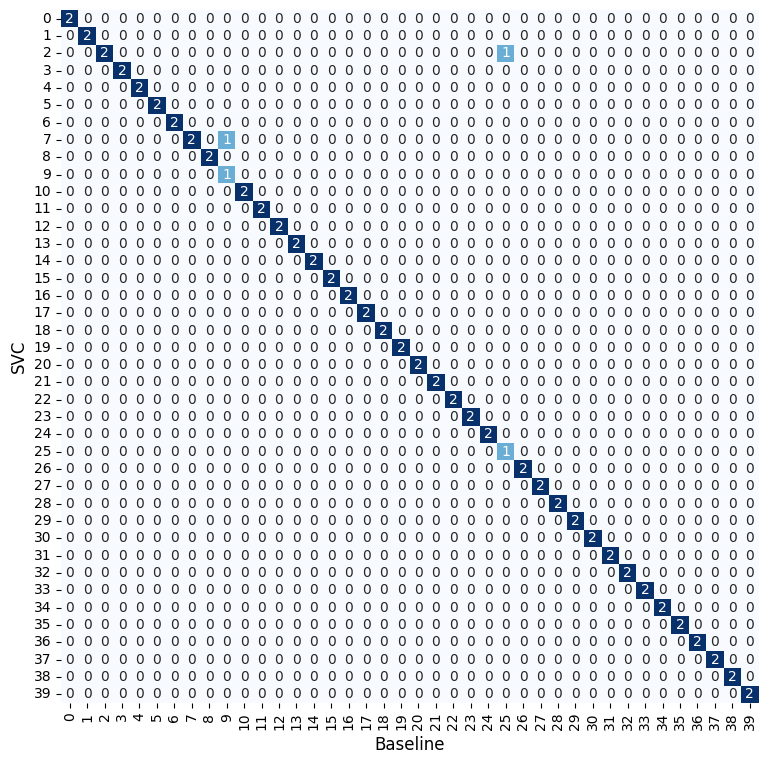

In [139]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
import seaborn as sns

svc = make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=69))
start = time.time()
svc.fit(X_train_pca, y_train)
svc_time = time.time() - start
svc_pred = svc.predict(X_test_pca)
svc_accuracy = accuracy_score(y_test, svc_pred)
print('Test Accuracy: ', svc_accuracy)
print('Test Time: ', svc_time)
print('Baseline vs. SVC')
types = ["Baseline", "SVC"]
cm = confusion_matrix(y_pred_pca, svc_pred)
plt.figure(figsize=(9, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Baseline', fontsize=12)
plt.ylabel('SVC', fontsize=12)
plt.show

# **Task 7: Ensemble Classification on PCA Features** Construct a VotingClassifier (soft voting) combining a Polynomial Kernel SVM (degree=2), an RBF Kernel SVM, and a RandomForestClassifier (n_estimators=100). Train the ensemble on the PCA-reduced features, record training time and accuracy, and compare its performance against the single linear and non-linear models.

Here I used the same time function as previous to start, which I then use to time the process of creating the classifiers, putting them in the Voting Classifier, and fiting the data to it. I then make the accuracy score and print it alongside the previous PCA results for comparison.

In [140]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier

print("Training Ensemble Classifier on PCA-reduced features...")
start_time = time.time()
svc_poly = SVC(kernel="poly", degree=2, probability=True, random_state=69)
svc_rbf = SVC(kernel='rbf', probability=True, random_state=69)
rf = RandomForestClassifier(n_estimators=100, random_state=69)
ensemble_clf = VotingClassifier(estimators=[
        ('poly_svm', svc_poly),
        ('rbf_svm', svc_rbf),
        ('random_forest', rf)
    ], voting='soft')
ensemble_clf.fit(X_train_pca, y_train)
ensemble_time = time.time() - start_time
y_pred_ensemble = ensemble_clf.predict(X_test_pca)
ensemble_accuracy = accuracy_score(y_test, y_pred_ensemble)
print('Test Accuracy: ', ensemble_accuracy)
print('Test Time: ', ensemble_time)
print(' ')
print("Baseline and SVC for Comparison")
print('PCA Test Accuracy: ', pca_accuracy)
print('PCA Test Time: ', pca_time)
print('SVC Test Accuracy: ', svc_accuracy)
print('SVC Test Time: ', svc_time)

Training Ensemble Classifier on PCA-reduced features...
Test Accuracy:  0.9625
Test Time:  1.005528211593628
 
Baseline and SVC for Comparison
PCA Test Accuracy:  0.975
PCA Test Time:  0.7788662910461426
SVC Test Accuracy:  1.0
SVC Test Time:  0.20006775856018066


# **Task 8: Comprehensive Comparative Evaluation** Create a single summary bar plot comparing Accuracy (primary y-axis) and Training Time in seconds (secondary y-axis) across all four model configurations:

## 1. Logistic Regression (Raw Features)

## 2. Logistic Regression (PCA-Reduced)

## 3. Support Vector Classifier with RBF Kernel (PCA-Reduced)

## 4. Soft Voting Ensemble (PCA-Reduced)

For this I simply used the plot from task 5 and added two more bar positions, as well as editing the colors so I don't need to add double the amount of color.

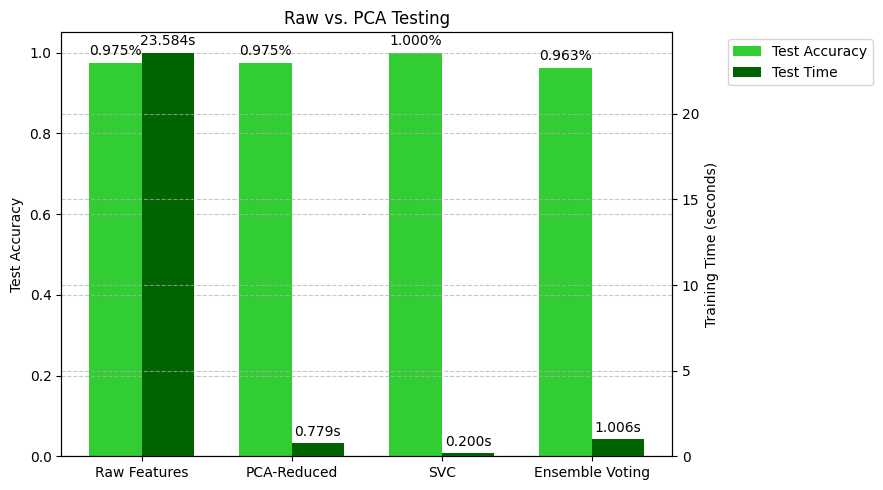

In [141]:
fig, ax1 = plt.subplots(figsize=(9, 5))
width = 0.35
labels = ["Raw Features", "PCA-Reduced", "SVC", "Ensemble Voting"]
positions = np.arange(len(labels))
bars_acc = ax1.bar(positions - width / 2, [raw_accuracy, pca_accuracy, svc_accuracy, ensemble_accuracy], width, color=["limegreen"], label="Test Accuracy")
ax1.set_ylabel("Test Accuracy")
ax1.set_title("Raw vs. PCA Testing")
ax1.set_ylim(0, 1.05)
ax1.grid(axis="y", linestyle="--", alpha=0.7)
ax1.set_xticks(positions)
ax1.set_xticklabels(labels)
ax1.bar_label(bars_acc, fmt="%.3f%%", padding=3)
ax2 = ax1.twinx()
positions = np.arange(len(labels))
bars_time = ax2.bar(positions + (width / 2), [raw_time, pca_time, svc_time, ensemble_time], width, color=["darkgreen"], label = "Test Time")
ax2.set_ylabel("Training Time (seconds)")
ax2.grid(axis="y", linestyle="--", alpha=0.7)
ax2.bar_label(bars_time, fmt="%.3fs", padding=3)
handles = [bars_acc, bars_time]
hlabels = [h.get_label() for h in handles]
ax1.legend(handles, hlabels, loc="upper left", bbox_to_anchor=(1.08, 1), frameon=True,)
plt.tight_layout()
plt.show()